# Códidgo de la reconstrucción de los parámetros internos de un plasma usando el algoritmo de Metropolis-Hastings

Para este avance, se va a mantener que el parámetro A es conocido, por lo tanto solo se buscará reconstruir $\varepsilon$, $\kappa$ y $\delta$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sc
import time

## Solución analítica

### Minimizar la siguiente celda:
Son los cálculos de los coeficientes 7 coeficientes $c_i$, las expresiones se calcularon con wxMaxima. El archivoo con los cálculos está en el mismo repositorioo que este notebook.

In [2]:
def calc_ci(eps, kappa, delta, A):
    # Función para calcular los coeficientes de la solución analítica c_i, i = 1,2,..,7
    alpha = np.arcsin(delta)
    N1 = -((1+alpha)**2)/(eps*kappa**2)
    N2 = ((1-alpha)**2)/(eps*kappa**2)
    N3 = -kappa/(eps*np.cos(alpha)**2)
    # Estas expresiones se calcularon con wxMaxima
    #--------------------------------------------------------------------------------------------------------
    coef_eq1 = np.array([
        1,
        eps**2 + 2*eps + 1,
        (-eps**2 - 2*eps - 1) * np.log(eps + 1),
        eps**4 + 4*eps**3 + 6*eps**2 + 4*eps + 1,
        (3*eps**4 + 12*eps**3 + 18*eps**2 + 12*eps + 3) * np.log(eps + 1),
        eps**6 + 6*eps**5 + 15*eps**4 + 20*eps**3 + 15*eps**2 + 6*eps + 1,
        (-(15*eps**6) - 90*eps**5 - 225*eps**4 - 300*eps**3 - 225*eps**2 - 90*eps - 15) * np.log(eps + 1)])
    #--------------------------------------------------------------------------------------------------------
    coef_eq2 = np.array([
        1,
        eps**2 - 2*eps + 1,
        -(np.log(1 - eps) * eps**2) + 2*np.log(1 - eps)*eps - np.log(1 - eps),
        eps**4 - 4*eps**3 + 6*eps**2 - 4*eps + 1,
        3*np.log(1 - eps)*eps**4 - 12*np.log(1 - eps)*eps**3
            + 18*np.log(1 - eps)*eps**2 - 12*np.log(1 - eps)*eps
            + 3*np.log(1 - eps),
        eps**6 - 6*eps**5 + 15*eps**4 - 20*eps**3 + 15*eps**2 - 6*eps + 1,
        -(15*np.log(1 - eps)*eps**6) + 90*np.log(1 - eps)*eps**5
            - 225*np.log(1 - eps)*eps**4 + 300*np.log(1 - eps)*eps**3
            - 225*np.log(1 - eps)*eps**2 + 90*np.log(1 - eps)*eps
            - 15*np.log(1 - eps)])

    #--------------------------------------------------------------------------------------------------------
    L = np.log(1 - delta*eps)

    coef_eq3 = np.array([
        1,
        delta**2*eps**2 - 2*delta*eps + 1,
        eps**2*kappa**2 + (-(delta**2*eps**2) + 2*delta*eps - 1)*L,
        (-(4*delta**2*eps**4) + 8*delta*eps**3 - 4*eps**2)*kappa**2
            + delta**4*eps**4 - 4*delta**3*eps**3
            + 6*delta**2*eps**2 - 4*delta*eps + 1,
        2*eps**4*kappa**4
            + ((-(12*delta**2*eps**4) + 24*delta*eps**3 - 12*eps**2)*L
               - 9*delta**2*eps**4 + 18*delta*eps**3 - 9*eps**2)*kappa**2
            + (3*delta**4*eps**4 - 12*delta**3*eps**3
               + 18*delta**2*eps**2 - 12*delta*eps + 3)*L,
        (8*delta**2*eps**6 - 16*delta*eps**5 + 8*eps**4)*kappa**4
            + (-(12*delta**4*eps**6) + 48*delta**3*eps**5
               - 72*delta**2*eps**4 + 48*delta*eps**3 - 12*eps**2)*kappa**2
            + delta**6*eps**6 - 6*delta**5*eps**5 + 15*delta**4*eps**4
              - 20*delta**3*eps**3 + 15*delta**2*eps**2 - 6*delta*eps + 1,
        8*eps**6*kappa**6
            + ((-(120*delta**2*eps**6) + 240*delta*eps**5 - 120*eps**4)*L
               - 140*delta**2*eps**6 + 280*delta*eps**5 - 140*eps**4)*kappa**4
            + ((180*delta**4*eps**6 - 720*delta**3*eps**5
                + 1080*delta**2*eps**4 - 720*delta*eps**3 + 180*eps**2)*L
               + 75*delta**4*eps**6 - 300*delta**3*eps**5
               + 450*delta**2*eps**4 - 300*delta*eps**3 + 75*eps**2)*kappa**2
            + (-(15*delta**6*eps**6) + 90*delta**5*eps**5
               - 225*delta**4*eps**4 + 300*delta**3*eps**3
               - 225*delta**2*eps**2 + 90*delta*eps - 15)*L])
    
    #--------------------------------------------------------------------------------------------------------
    L = np.log(1 - delta*eps)
    coef_eq4 = np.array([
        0,
        2 - 2*delta*eps,
        (2*delta*eps - 2)*L + delta*eps - 1,
        (8*delta*eps**3 - 8*eps**2)*kappa**2 - 4*delta**3*eps**3 + 12*delta**2*eps**2 - 12*delta*eps + 4,
        ((24*delta*eps**3 - 24*eps**2)*L + 30*delta*eps**3 - 30*eps**2)*kappa**2
            + (-(12*delta**3*eps**3) + 36*delta**2*eps**2 - 36*delta*eps + 12)*L
            - 3*delta**3*eps**3 + 9*delta**2*eps**2 - 9*delta*eps + 3,
        (16*eps**4 - 16*delta*eps**5)*kappa**4
            + (48*delta**3*eps**5 - 144*delta**2*eps**4
               + 144*delta*eps**3 - 48*eps**2)*kappa**2
            - 6*delta**5*eps**5 + 30*delta**4*eps**4 - 60*delta**3*eps**3
            + 60*delta**2*eps**2 - 30*delta*eps + 6,
        ((240*delta*eps**5 - 240*eps**4)*L + 400*delta*eps**5 - 400*eps**4)*kappa**4
            + ((-(720*delta**3*eps**5) + 2160*delta**2*eps**4
                - 2160*delta*eps**3 + 720*eps**2)*L
               - 480*delta**3*eps**5 + 1440*delta**2*eps**4
               - 1440*delta*eps**3 + 480*eps**2)*kappa**2
            + (90*delta**5*eps**5 - 450*delta**4*eps**4
               + 900*delta**3*eps**3 - 900*delta**2*eps**2
               + 450*delta*eps - 90)*L
            + 15*delta**5*eps**5 - 75*delta**4*eps**4
              + 150*delta**3*eps**3 - 150*delta**2*eps**2
              + 75*delta*eps - 15])
    
    #--------------------------------------------------------------------------------------------------------
    L = np.log(eps + 1)
    den = eps*kappa**2
    coef_eq5 = np.array([
        0,
        -(((2*alpha**2 + 4*alpha + 2)*eps + 2*alpha**2 + 4*alpha + 2) / den),
        (2*eps*kappa**2
            + ((2*alpha**2 + 4*alpha + 2)*eps + 2*alpha**2 + 4*alpha + 2)*L
            + (alpha**2 + 2*alpha + 1)*eps + alpha**2 + 2*alpha + 1) / den,
        -(((8*eps**3 + 16*eps**2 + 8*eps)*kappa**2
            + (4*alpha**2 + 8*alpha + 4)*eps**3
            + (12*alpha**2 + 24*alpha + 12)*eps**2
            + (12*alpha**2 + 24*alpha + 12)*eps
            + 4*alpha**2 + 8*alpha + 4) / den),
        -((((24*eps**3 + 48*eps**2 + 24*eps)*L
             + 18*eps**3 + 36*eps**2 + 18*eps)*kappa**2
            + ((12*alpha**2 + 24*alpha + 12)*eps**3
               + (36*alpha**2 + 72*alpha + 36)*eps**2
               + (36*alpha**2 + 72*alpha + 36)*eps
               + 12*alpha**2 + 24*alpha + 12)*L
            + (3*alpha**2 + 6*alpha + 3)*eps**3
            + (9*alpha**2 + 18*alpha + 9)*eps**2
            + (9*alpha**2 + 18*alpha + 9)*eps
            + 3*alpha**2 + 6*alpha + 3) / den),
        -(((24*eps**5 + 96*eps**4 + 144*eps**3 + 96*eps**2 + 24*eps)*kappa**2
            + (6*alpha**2 + 12*alpha + 6)*eps**5
            + (30*alpha**2 + 60*alpha + 30)*eps**4
            + (60*alpha**2 + 120*alpha + 60)*eps**3
            + (60*alpha**2 + 120*alpha + 60)*eps**2
            + (30*alpha**2 + 60*alpha + 30)*eps
            + 6*alpha**2 + 12*alpha + 6) / den),
        (((360*eps**5 + 1440*eps**4 + 2160*eps**3 + 1440*eps**2 + 360*eps)*L
            + 150*eps**5 + 600*eps**4 + 900*eps**3 + 600*eps**2 + 150*eps)*kappa**2
            + ((90*alpha**2 + 180*alpha + 90)*eps**5
               + (450*alpha**2 + 900*alpha + 450)*eps**4
               + (900*alpha**2 + 1800*alpha + 900)*eps**3
               + (900*alpha**2 + 1800*alpha + 900)*eps**2
               + (450*alpha**2 + 900*alpha + 450)*eps
               + 90*alpha**2 + 180*alpha + 90)*L
            + (15*alpha**2 + 30*alpha + 15)*eps**5
            + (75*alpha**2 + 150*alpha + 75)*eps**4
            + (150*alpha**2 + 300*alpha + 150)*eps**3
            + (150*alpha**2 + 300*alpha + 150)*eps**2
            + (75*alpha**2 + 150*alpha + 75)*eps
            + 15*alpha**2 + 30*alpha + 15) / den])

    #--------------------------------------------------------------------------------------------------------
    L = np.log(1 - eps)
    den = eps*kappa**2
    coef_eq6 = np.array([
        0,
        -(((2*alpha**2 - 4*alpha + 2)*eps - 2*alpha**2 + 4*alpha - 2) / den),
        (2*eps*kappa**2
            + ((2*alpha**2 - 4*alpha + 2)*L + alpha**2 - 2*alpha + 1)*eps
            + (-(2*alpha**2) + 4*alpha - 2)*L
            - alpha**2 + 2*alpha - 1) / den,
        -(((8*eps**3 - 16*eps**2 + 8*eps)*kappa**2
            + (4*alpha**2 - 8*alpha + 4)*eps**3
            + (-(12*alpha**2) + 24*alpha - 12)*eps**2
            + (12*alpha**2 - 24*alpha + 12)*eps
            - 4*alpha**2 + 8*alpha - 4) / den),
        -((((24*L + 18)*eps**3
             + (-(48*L) - 36)*eps**2
             + (24*L + 18)*eps)*kappa**2
            + ((12*alpha**2 - 24*alpha + 12)*L + 3*alpha**2 - 6*alpha + 3)*eps**3
            + ((-(36*alpha**2) + 72*alpha - 36)*L - 9*alpha**2 + 18*alpha - 9)*eps**2
            + ((36*alpha**2 - 72*alpha + 36)*L + 9*alpha**2 - 18*alpha + 9)*eps
            + (-(12*alpha**2) + 24*alpha - 12)*L
            - 3*alpha**2 + 6*alpha - 3) / den),
        -(((24*eps**5 - 96*eps**4 + 144*eps**3 - 96*eps**2 + 24*eps)*kappa**2
            + (6*alpha**2 - 12*alpha + 6)*eps**5
            + (-(30*alpha**2) + 60*alpha - 30)*eps**4
            + (60*alpha**2 - 120*alpha + 60)*eps**3
            + (-(60*alpha**2) + 120*alpha - 60)*eps**2
            + (30*alpha**2 - 60*alpha + 30)*eps
            - 6*alpha**2 + 12*alpha - 6) / den),
        (((360*L + 150)*eps**5
            + (-(1440*L) - 600)*eps**4
            + (2160*L + 900)*eps**3
            + (-(1440*L) - 600)*eps**2
            + (360*L + 150)*eps)*kappa**2
            + ((90*alpha**2 - 180*alpha + 90)*L + 15*alpha**2 - 30*alpha + 15)*eps**5
            + ((-(450*alpha**2) + 900*alpha - 450)*L - 75*alpha**2 + 150*alpha - 75)*eps**4
            + ((900*alpha**2 - 1800*alpha + 900)*L + 150*alpha**2 - 300*alpha + 150)*eps**3
            + ((-(900*alpha**2) + 1800*alpha - 900)*L - 150*alpha**2 + 300*alpha - 150)*eps**2
            + ((450*alpha**2 - 900*alpha + 450)*L + 75*alpha**2 - 150*alpha + 75)*eps
            + (-(90*alpha**2) + 180*alpha - 90)*L
            - 15*alpha**2 + 30*alpha - 15) / den])
    
    #--------------------------------------------------------------------------------------------------------
    L  = np.log(1 - delta*eps)
    ca = np.cos(alpha)
    ca2 = ca**2
    den = ca2
    coef_eq7 = np.array([
        0,
        2,
        -((2*kappa**2 + 2*ca2*L + 3*ca2) / den),
        (((8*delta**2 - 8*ca2)*eps**2 - 16*delta*eps + 8)*kappa**2
            + 12*ca2*delta**2*eps**2 - 24*ca2*delta*eps + 12*ca2) / den,
        -((8*eps**2*kappa**4
            + (((24*ca2 - 24*delta**2)*eps**2 + 48*delta*eps - 24)*L
               + (54*ca2 - 18*delta**2)*eps**2 + 36*delta*eps - 18)*kappa**2
            + (-(36*ca2*delta**2*eps**2) + 72*ca2*delta*eps - 36*ca2)*L
            - 21*ca2*delta**2*eps**2 + 42*ca2*delta*eps - 21*ca2) / den),
        -((((32*delta**2 - 16*ca2)*eps**4 - 64*delta*eps**3 + 32*eps**2)*kappa**4
            + ((144*ca2*delta**2 - 24*delta**4)*eps**4
               + (96*delta**3 - 288*ca2*delta)*eps**3
               + (144*ca2 - 144*delta**2)*eps**2
               + 96*delta*eps - 24)*kappa**2
            - 30*ca2*delta**4*eps**4 + 120*ca2*delta**3*eps**3
            - 180*ca2*delta**2*eps**2 + 120*ca2*delta*eps - 30*ca2) / den),
        -((48*eps**4*kappa**6
            + (((240*ca2 - 480*delta**2)*eps**4
                + 960*delta*eps**3 - 480*eps**2)*L
               + (640*ca2 - 560*delta**2)*eps**4
               + 1120*delta*eps**3 - 560*eps**2)*kappa**4
            + (((360*delta**4 - 2160*ca2*delta**2)*eps**4
                + (4320*ca2*delta - 1440*delta**3)*eps**3
                + (2160*delta**2 - 2160*ca2)*eps**2
                - 1440*delta*eps + 360)*L
               + (150*delta**4 - 2160*ca2*delta**2)*eps**4
               + (4320*ca2*delta - 600*delta**3)*eps**3
               + (900*delta**2 - 2160*ca2)*eps**2
               - 600*delta*eps + 150)*kappa**2
            + (450*ca2*delta**4*eps**4 - 1800*ca2*delta**3*eps**3
               + 2700*ca2*delta**2*eps**2 - 1800*ca2*delta*eps
               + 450*ca2)*L
            + 165*ca2*delta**4*eps**4 - 660*ca2*delta**3*eps**3
              + 990*ca2*delta**2*eps**2 - 660*ca2*delta*eps
              + 165*ca2) / den)])
    
    '''print(coef_eq1)
    print(coef_eq2)
    print(coef_eq3)
    print(coef_eq4)
    print(coef_eq5)
    print(coef_eq6)
    print(coef_eq7)
    print(coef_eq2.shape)'''

    b_eq1 = -(A * (((eps + 1)**2 * np.log(eps + 1)) / 2 - (eps + 1)**4 / 8) + (eps + 1)**4 / 8)
    b_eq2 = -( (1 - eps)**4 / 8 + A * ((np.log(1 - eps) * (1 - eps)**2) / 2 - (1 - eps)**4 / 8) )
    b_eq3 = -(A * (((1 - delta*eps)**2 * np.log(1 - delta*eps)) / 2 - (1 - delta*eps)**4 / 8) + (1 - delta*eps)**4 / 8)
    
    u = 1 - delta*eps
    b_eq4 = -(A * (u * np.log(u) - u**3 / 2 + u / 2) + u**3 / 2)
    
    u   = eps + 1
    den = eps * kappa**2
    b_eq5 = (((alpha + 1)**2 * (A * (u * np.log(u) - u**3 / 2 + u / 2) + u**3 / 2)) / den)

    u   = 1 - eps
    den = eps * kappa**2
    b_eq6 = -((1 - alpha)**2 * (A * (np.log(u)*u + u/2 - u**3/2) + u**3/2)) / den

    u = 1 - delta*eps
    b_eq7 = -(A * (np.log(u) - (3*u**2)/2 + 3/2) + (3*u**2)/2)

    
    
    M = np.vstack([coef_eq1,
                coef_eq2,
                coef_eq3,
                coef_eq4,
                coef_eq5,
                coef_eq6,
                coef_eq7])
    b = np.array([b_eq1,b_eq2,b_eq3,b_eq4,b_eq5,b_eq6,b_eq7])
    
    # Resuelve el sistema de ecuaciones de manera numérica
    c = np.linalg.solve(M, b)
    return c







    

In [3]:
def solAnalitica(x, y, A, c):
    # Expresión de la solución analítica
    phi2 = x**2
    phi3 = y**2 - x**2*np.log(x)
    phi4 = x**4 - 4 * x**2 * y**2
    phi5 = 2*y**4 - 9*y**2*x**2 + 3*x**4*np.log(x) - 12*x**2*y**2*np.log(x)
    phi6 = x**6 - 12*x**4 * y**2 + 8*x**2 * y**4
    phi7 = 8*y**6 - 140*y**4*x**2 + 75*y**2*x**4 - 15*x**6*np.log(x) + 180*x**4*y**2*np.log(x) - 120*x**2*y**4*np.log(x)

    return x**4/8+A*(1/2*x**2*np.log(x)-x**4/8)+c[0]+c[1]*phi2 + c[2]*phi3 + c[3]*phi4 + c[4]*phi5 + c[5]*phi6 +c[6]*phi7

## Código principal

In [4]:
def frontera(H, phi, func_ci, theta, N=45):
    # Calcula la frontera del plasma en un número de puntos para el conjunto de parámetros H
    # H: array con epsilon, kappa, delta y A
    # phi: función de la solución analítica
    # func_ci: función que calcula los coeficientes de la solución analítica
    # theta: floar o array de ángulo(s) a los que se encuentra cada detector del campo poloidal
    # output: float o array o  con la posición de la frontera en la dirección radial para el o los ángulos 
    
    eps, k, d, A = H
    c = func_ci(eps, k, d, A)

    # Precalculo los valores de cos(theta) y sin(theta) para buscar posteriormente los ceros
    costheta, sentheta = np.cos(theta) , np.sin(theta)
    phi_temp = lambda r: phi(1 + r*costheta, r*sentheta, A, c)

    # Método de bisección para encontrar el borde del plasma, o sea, donde phi=0
    lo = np.zeros(len(theta))                      # (1,0), dentro del plasma: psi < 0
    hi = np.full(len(theta), 1.5*eps*max(1.0, k))  # cota superior: fuera, psi > 0. El plasma tiene desde su eje, una extensión horizontal
                                                   # de epsilon, y de extensión vertical de kappa*epsilon
                                                   # Por eso el rangoo de la proposición inicial para la bisección se define desde un punto
                                                   # interior del plasma, donde phi<0, a uno exterior, donde phi>0, con el término superior
                                                   # dado por kappa*epsilon cuando kappa>1, o epsilon cuando kappa<1, multiplicado por 1.5 
                                                   # para dar un mayor margen en caso de valores muy cercanos a la frontera
    
    for i in range(N):
        mid = 0.5*(lo + hi)
        condicion = phi_temp(mid) < 0
        lo = np.where(condicion, mid, lo)
        hi = np.where(condicion, hi, mid)

    return (lo + hi)/2



def ruido_gaussiano(data, sigma, rng = np.random.default_rng()):
    # Funcion para añadir ruido gaussiano a los datos originales (no hace falta la función, me acabo de dar cuenta, después lo cambio xd)
    # data: dato original, es el valor de expectación de la gaussiana
    # sigma: raiz de la varianza
    # rng: generador de la variable aleatoria
    # output: array con los datos sucios
    return rng.normal(loc = data, scale = sigma)

def prop_H0(limites=np.full(4,None), epsilon=None, kappa=None, delta=None, A=None, rng = np.random.default_rng()):
    # Función para dar los valores iniciales de la cadena. Se realizó así para simplificar el como fijar uno o varios parámetros
    # de manera arbritraria en el caso de que no se quiera que todos sean dados de manera aleatoria bajo el rango físico válido.
    # limites: Si no es None, array de arrays que contienen el límite inferior y superior del rango de cada parámetro
    # epsilon: Si no es None, float con el valor inicial del parámetro epsilon que se quiera usar en el valor inicial de la cadena
    # kappa: Si no es None, float con el valor inicial del parámetro kappa que se quiera en el valor inicial de la cadena
    # delta: Si no es None, float con el valor inicial del parámetro delta que se quiera usar en el valor inicial de la cadena
    # A: Si no es None, float con el valor inicial del parámetro A que se quiera usar en el valor inicial de la cadena
    # output: array con los valores iniciales de la cadena
    H0 = np.zeros(4)
    if limites.all() != None:
        H0 = np.array([rng.uniform(lim_params[0][0], lim_params[0][1]),  rng.uniform(lim_params[1][0],lim_params[1][1]), 
                         rng.uniform(lim_params[2][0], lim_params[2][1]), rng.uniform(lim_params[3][0], lim_params[3][1])])
    if epsilon != None:
        H0[0] = epsilon
    if kappa != None:
        H0[1] = kappa
    if delta != None:
        H0[2] = delta
    if A != None:
        H0[3] = A
    return H0
        
def log_compLikelihoods(D, d_old, d_new, sigma):
    # Función que calcula el logaritmo natural de la relación de las likelihood functions, ya en su forma simplificada.
    # D: Datos originales (con ruido)
    # d_old: Datos propuestos por el paso anterior de la cadena
    # d_new: Datos propuestos por el paso actual de la cadena
    # sigma: array con las desviaciones estandar de cada dato
    # output: float con el valor del criterio de metropolis para el estado actual y el propuesto
    return np.sum( 1/(2*sigma**2) * ( (D - d_old)**2 - (D - d_new)**2 ) )



def propH(Hi, ancho, rng = np.random.default_rng(11), fixeps = (False, 0.0),fixkappa = (False, 0.0), fixdelta = (False, 0.0) ,fixA = (False, 0.0)):
    # Función para variar los 4 parámetros al mismo tiempo.
    # Hi : array de parámetros en el estado actual
    # ancho : array con los anchos de la variación de cada parámetro
    # rng : el generador de números aleatorios
    # fix* : tupla que define si tenemos el parámetro * como fijo, o sea, si este es conocido.
    # output : el nuevo vector de prueba (priori) de los parámetros
    H_temp = rng.normal(Hi,ancho)

    # Esto es por el momento para hacer pruebas, después lo quito
    if fixeps[0] == True:
        H_temp[0] = fixeps[1]
    if fixkappa[0] == True:
        H_temp[1] = fixkappa[1]
    if fixdelta[0] == True:
        H_temp[2] = fixdelta[1]
    if fixA[0] == True:
        H_temp[3] = fixA[1]

    return H_temp

    

def hist_parametro(muestras, j, xlabel, valor_real=None, bins=40, save=False, savepath='Histogramas/'):
    # Histograma de la cadena para un parámetro.
    # muestras: array con las muestras
    # j: índice del parámetro (0: epsilon, 1: kappa, 2: delta, 3: A)
    # xlabel: texto para el eje x
    # valor_real: valor con el que se generaron los datos (línea vertical)
    if j == 0:
        param = 'epsilon'
        plt.hist(muestras[:, j], color = 'b', bins=bins, density=True, alpha=0.6)
    if j == 1:
        param = 'kappa'
        plt.hist(muestras[:, j], color = 'c',bins=bins, density=True, alpha=0.6)
    if j == 2:
        param = 'delta'
        plt.hist(muestras[:, j], color = 'g',bins=bins, density=True, alpha=0.6)
    if j == 3:
        param = 'A'
        plt.hist(muestras[:, j], color = 'y',bins=bins, density=True, alpha=0.6)
    
    if valor_real is not None:
        plt.axvline(valor_real, color="r", label=f"real = {valor_real:.3g}")
    plt.axvline(muestras[:,j].mean(), color="k", ls="--", label=f"promedio = {muestras[:,j].mean():.3g}")
    plt.xlabel(f'{xlabel}')
    plt.legend()
    if save == True:
  
            
        plt.savefig(f'{savepath}HistogramaMH_{param}_{valor_real}_m_{len(muestras[:, j])}.pdf')
    plt.show()
    plt.clf()



def promedio_muestras(X):
    # Función para calcular el promedio de la cadena o funciones aplicadas sobre esta
    # X: Array con la cadena de markov generada
    # output: float con el promedio de la cadena
    return np.array([np.mean(X[:,0]), np.mean(X[:,1]), np.mean(X[:,2]), np.mean(X[:,3])])


## Parámetros de los detectores falsos (no sé aún como llamarle a estos puntos xd)

In [5]:
# Para los puntos de frontera, donde el flujo poloidal se hace 0, hay num_pto_frontera puntos de detección, equidistantes en su ángulo
num_ptos_frontera = 12

theta = np.linspace(0,2*np.pi, num_ptos_frontera, endpoint=False)

# Límites físicos de los parámetros
lim_eps = np.array([0.05, 0.99])
lim_kappa = np.array([0.001, 15]) # Realmente kappa solo tiene que ser positivo
lim_delta = np.array([-np.sin(1),np.sin(1)])
lim_A = np.array([-3,3]) # Este es solo para el estado inicial, por el momento no se va acotar como tal

lim_params = np.array([lim_eps, lim_kappa, lim_delta, lim_A])


## Generamos los datos reales

In [6]:
# Parámetros del ITER

epsilon_r = 0.32
kappa_r = 1.7
delta_r = 0.33
A_r = -0.155

# Parámetros del un Tokamak Esférico: NSTX (National Spherical Torus Experiment)
'''
epsilon_r = 0.78
kappa_r = 2
delta_r = 0.35
A_r = -0.05
'''

# Parámetros para FRC (Field Reversed Configuration)
# Este caso aún no se ha provado completamente, ya que es muy diferentes a los anteriores, solo lo puse por el momento para ir dejando listo
# las cosas para ese caso
'''
epsilon_r = 0.99
kappa_r = 10
delta_r = 0.7
A_r = 0
lim_params[0] = np.array([0.05, 0.999]) #  Se necesita un valor más cerca de 1 en el rango puesto que el valor real se aproxima a 1
'''

H_real = [epsilon_r, kappa_r, delta_r, A_r]


sigma_fronteras = 0.1 # Desviación estándar de las mediciones del flujo en la fronteras


# Datos de hasta donde está la frontera del plasma con los parámetros originales
radios_front = frontera(H_real, solAnalitica, calc_ci, theta)


# Se ensucian los datos de la frontera para "ocultar" los datos originales
D_frontera = ruido_gaussiano(radios_front, sigma_fronteras, rng = np.random.default_rng(11))
print(radios_front)
print(D_frontera)


[0.32       0.31958361 0.34394054 0.44072428 0.57582063 0.36821119
 0.32       0.36821119 0.57582063 0.44072428 0.34394054 0.31958361]
[0.32341928 0.45555837 0.46641265 0.38969357 0.54602368 0.31547277
 0.37697264 0.36260475 0.65050919 0.2559918  0.50059542 0.3099404 ]


## Implementación de la MCMC

In [7]:
#rngH0 = np.random.default_rng(123)
#rngU = np.random.default_rng(11)
#rngpropH = np.random.default_rng(42)
rngH0 = np.random.default_rng()
rngU = np.random.default_rng()
rngpropH = np.random.default_rng()

Nota: A veces esta celda salta un error para algún conjunto de parámetros, se puede  ignorar traanquilamente, esos casos son cuando el conjunto tiene una convinación que sus parámetros sí están dentro del rango, pero su combinaación no, y causan que se indefina el log(x) de la solución analítica. Estos casos se descartan por el criterio de metropolis.

In [8]:
m = 60000 # Número de pasos de la cadena
rango_var = [0.03,0.09,0.02,0.02] # Que tanto puede moverse cada parámetro (ajustar), van en el orden de H 
#rango_var = [0.03, 0.1, 0.1, 0.5]
H = np.zeros((m,4), dtype=float)


start = time.time()

# Se propone el estado inicial de la cadena

#H[0] = prop_H0(epsilon = 0.1, kappa=10, delta=0.80, A=A_r)
H[0] = prop_H0(limites=lim_params, A=A_r, rng = rngH0)

# Se calculan los datos predichos por el estado inicial de la cadena
d_old = frontera(H[0], solAnalitica, calc_ci, theta)


rechazos_inval_param = 0 # Contador para número de rechazos por parámetros no físicamente viables
cont_param_posibles = 0 # Contador total de parámetros físicamente viables
rechazos_priori = 0 # Contador paraa número de rechazos de parámetros físicamente viables, pero que no pasan el cirterio de metroopolis

for i in range(0,m-1):
    U = rngU.random()
    # Se propone un nuevo vector-estado H
    H_new = propH(H[i], rango_var, rng = rngpropH, fixeps = (False, epsilon_r),fixkappa = (False, kappa_r), fixdelta = (False, delta_r), fixA = (True, A_r))
    # Si los parámetros de H no son físicamente viables, se rechazan de una vez
    if H_new[0] < lim_params[0][0] or H_new[0] > lim_params[0][1] or H_new[1] < lim_params[1][0] or H_new[1] > lim_params[1][1] or H_new[2] < lim_params[2][0] or H_new[2] > lim_params[2][1] or H_new[3] < lim_params[3][0] or H_new[3] > lim_params[3][1]:
        H[i+1] = H[i]
        rechazos_inval_param += 1
    else:
        # Si los parámetros propuesto sí son viables se  calcula las fronteras del la función de flujo para estos parámetros
        d_new = frontera(H_new, solAnalitica, calc_ci, theta)

        # Se calcula la función de aceptación, se tuvo que usar logaritmo natural porque la productoria de la likelihood function original
        # hacia valores muy pequeños que causan problemas al evaluar en pasos futuros.
        lnr = log_compLikelihoods(D_frontera, d_old, d_new, sigma_fronteras)

        cont_param_posibles += 1

        # Se aplica el criterio de metropolis
        if np.log(U) < lnr:
            H[i+1] = H_new
            d_old = d_new
        else:
            H[i+1] = H[i]
            rechazos_priori += 1

end = time.time()


/tmp/ipykernel_66363/3909828593.py:4: RuntimeWarning: invalid value encountered in log
  phi3 = y**2 - x**2*np.log(x)
/tmp/ipykernel_66363/3909828593.py:6: RuntimeWarning: invalid value encountered in log
  phi5 = 2*y**4 - 9*y**2*x**2 + 3*x**4*np.log(x) - 12*x**2*y**2*np.log(x)
/tmp/ipykernel_66363/3909828593.py:8: RuntimeWarning: invalid value encountered in log
  phi7 = 8*y**6 - 140*y**4*x**2 + 75*y**2*x**4 - 15*x**6*np.log(x) + 180*x**4*y**2*np.log(x) - 120*x**2*y**4*np.log(x)
/tmp/ipykernel_66363/3909828593.py:10: RuntimeWarning: invalid value encountered in log
  return x**4/8+A*(1/2*x**2*np.log(x)-x**4/8)+c[0]+c[1]*phi2 + c[2]*phi3 + c[3]*phi4 + c[4]*phi5 + c[5]*phi6 +c[6]*phi7


In [9]:
print(f'Número de rechazos por parámetros fuera del rango físicamente valido: {rechazos_inval_param}')
print(f'Número de rechazos por comparación del prior (rechazo por criterio de metropolis): {rechazos_priori}')
print(f'Porcentaje de aceptación de datos priori: {100-rechazos_priori/cont_param_posibles*100}%')
print(f'Tiempo de ejecución: {end-start}')

Número de rechazos por parámetros fuera del rango físicamente valido: 851
Número de rechazos por comparación del prior (rechazo por criterio de metropolis): 24144
Porcentaje de aceptación de datos priori: 59.18036112801786%
Tiempo de ejecución: 152.3466956615448


In [10]:
# Quitamos el burn-in de la cadena
k = int(0.2*m) # Por el momento voy a suponer que el burn-in es el primer 20% de la cadena
cadena_filtrada = H[k:]

## Graficamos las distribuciones de la cadena

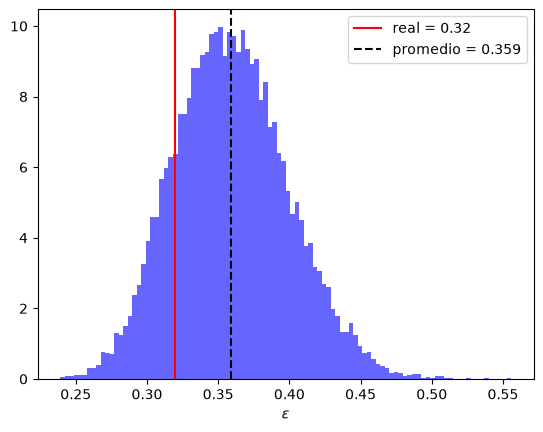

<Figure size 640x480 with 0 Axes>

In [11]:
bins = 100
hist_parametro(cadena_filtrada, 0, r'$\epsilon$', valor_real=epsilon_r, bins=bins, save = False)

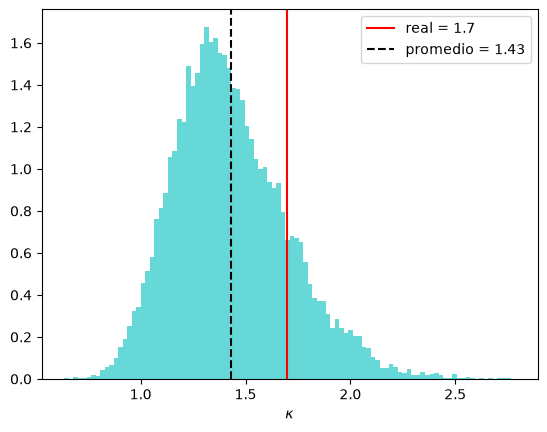

<Figure size 640x480 with 0 Axes>

In [12]:
hist_parametro(cadena_filtrada, 1, r'$\kappa$', valor_real=kappa_r, bins=bins, save = False)

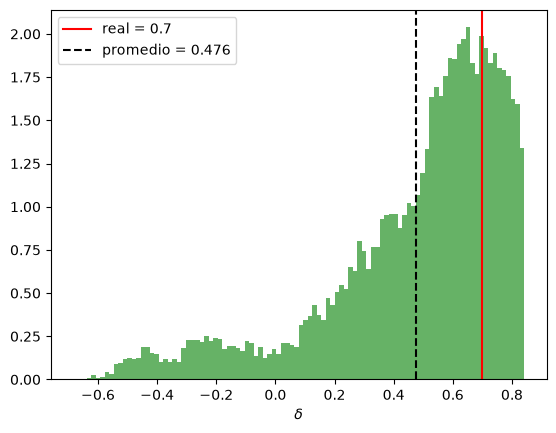

<Figure size 640x480 with 0 Axes>

In [13]:
hist_parametro(cadena_filtrada, 2, r'$\delta$', valor_real=delta_r, bins=bins, save = False)

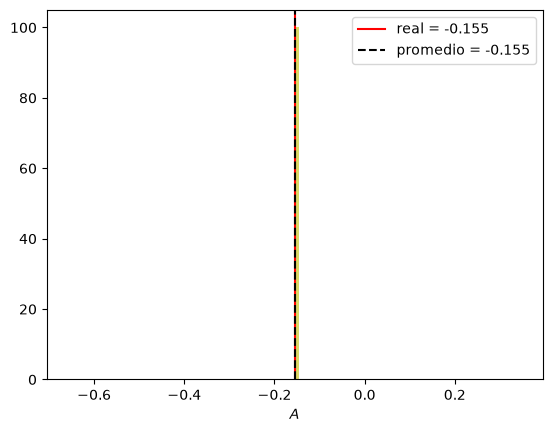

<Figure size 640x480 with 0 Axes>

In [14]:
hist_parametro(cadena_filtrada, 3, r'$A$', valor_real=A_r, bins=bins, save = False)

In [15]:
# Valor de expectación

promedios = promedio_muestras(cadena_filtrada) # Promedio simple de la cadena <X>

print(f'Promedio de epsilon: {promedios[0]:.3f}') 
print(f'Promedio de kappa: {promedios[1]:.3f}') 
print(f'Promedio de delta: {promedios[2]:.3f}') 
print(f'Promedio de A: {promedios[3]:.3f}') 

Promedio de epsilon: 0.359
Promedio de kappa: 1.431
Promedio de delta: 0.476
Promedio de A: -0.155
